# Volatility forecasting: next-week variance of the book and its positions

Out-of-sample forecasts from January 2018 to October 2026 (gold table `fact_forecast`), produced by [`pipeline/vol_models.py`](../pipeline/vol_models.py).

**Target.** The mean squared daily EUR return over the next 5 trading days, for each of the six positions and for the book (returns in percent). It is the variance input of the 1-day VaR built in the next step.

**Models.**
- EWMA (RiskMetrics, λ = 0.94).
- GARCH(1,1) and GJR-GARCH(1,1), which adds a leverage term (a fall raises volatility more than a rise), both with Student-t errors.
- HAR (Corsi, 2009) on the daily, weekly and monthly means of squared returns, in logs.
- HAR-range: the same regression on range-based variances (Garman and Klass, 1980, plus the overnight gap of Yang and Zhang, 2000), for the four positions with open, high, low and close.
- XGBoost on the HAR and range terms, the size and sign of the day's return, the VIX and the US and euro curve slopes (10y − 2y).
- A GRU reading 22-day sequences of the same features.

Log-target models are back-transformed with Duan's (1983) smearing factor.

**Validation.** Training on 2008–2017, then a refit at the start of every month on all past data (expanding window); supervised models leave out the last 5 training rows, whose targets overlap the forecast month. Losses: QLIKE (Patton, 2011), which ranks models consistently despite the noise of the squared-return proxy and penalises under-forecasts more, and squared error. Each model is compared with HAR by a Diebold-Mariano test with a Newey-West variance, on the same 2,269 days.

**Data note:** the VIX and the US 10y−2y slope come from FRED, offline on 21 October 2026 and downloaded on 22 October; they are inputs of XGBoost and the GRU only.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists())
sys.path.insert(0, str(ROOT))
from pipeline import evaluation, vol_models  # noqa: E402 - the pipeline's own losses and results table

GOLD = ROOT / "data" / "gold"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
MODEL_COLORS = {"gjr": "#2a78d6", "har": "#eb6834", "ewma": "#1baf7a"}
plt.rcParams.update(
    {
        "figure.figsize": (9, 3.6),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "lines.linewidth": 1.5,
        "legend.frameon": False,
        "font.size": 9,
    }
)

forecasts = pd.read_parquet(GOLD / "fact_forecast.parquet").assign(date=lambda d: pd.to_datetime(d["date"]))
names = pd.read_parquet(GOLD / "dim_position.parquet").set_index("position_id")["name"].to_dict() | {
    "book": "Book"
}
models = [m for m in vol_models.MODELS if m in set(forecasts["model_id"])]
table = vol_models.results_table(forecasts)
series_order = list(names)
print(
    f"{forecasts['date'].min():%d %b %Y} to {forecasts['date'].max():%d %b %Y}; models: {', '.join(models)}"
)

02 Jan 2018 to 20 Oct 2026; models: ewma, garch, gjr, har, har_range, xgboost, gru


## 1. Accuracy over 2018–2026

In [2]:
def by_series(period: str, value: str) -> pd.DataFrame:
    part = table[table["period"] == period].pivot(index="series_id", columns="model_id", values=value)
    return part.reindex(index=series_order, columns=models).rename(index=names)


qlike = by_series("2018-2026", "qlike")
print("Mean QLIKE, 2018-2026 (lower is better); best model per series:")
print(qlike.idxmin(axis=1).to_string())
qlike.round(3)

Mean QLIKE, 2018-2026 (lower is better); best model per series:
series_id
CAC 40                           xgboost
Euro Stoxx 50                    xgboost
S&P 500                          xgboost
Gold                                 gjr
10-year euro zero-coupon bond        gjr
USD cash                           garch
Book                                 gjr


model_id,ewma,garch,gjr,har,har_range,xgboost,gru
series_id,,,,,,,
CAC 40,0.541,0.491,0.467,0.515,0.450,0.437,0.512
Euro Stoxx 50,0.534,0.494,0.464,0.518,0.466,0.452,0.503
S&P 500,0.499,0.441,0.413,0.456,0.444,0.404,0.436
Gold,0.441,0.419,0.414,0.427,0.420,0.472,0.551
10-year euro zero-coupon bond,0.339,0.332,0.332,0.344,NaN,0.391,0.391
USD cash,0.368,0.351,0.352,0.373,NaN,0.402,0.415
Book,0.453,0.417,0.399,0.427,NaN,0.440,0.402


GJR-GARCH has the lowest QLIKE on the book (0.399, against 0.402 for the GRU and 0.427 for HAR), the bond and gold. The leverage term matters most for equities: against GARCH it lowers QLIKE by 5 to 6% on the CAC 40, the Euro Stoxx 50 and the S&P 500.

Range-based inputs improve HAR on the euro area indices (CAC 40: 0.450 against 0.515; Euro Stoxx 50: 0.466 against 0.518), much less on the S&P 500 (0.444 against 0.456) and gold (0.420 against 0.427). The two weaker cases are also the two with lower-quality prices: Yahoo records the S&P 500 open as the previous close on 9 to 26% of the days of 2011–2013, and 233 days of the gold front-month future have inconsistent highs and lows, replaced by squared returns.

With the VIX among its inputs, XGBoost is the most accurate model on the three equity indices (CAC 40 0.437, S&P 500 0.404, Euro Stoxx 50 0.452) but trails HAR on the bond, gold and the dollar. The GRU is not significantly more accurate than HAR on any series.

## 2. Are the differences significant?

In [3]:
statistic, p_value = by_series("2018-2026", "dm_stat_vs_har"), by_series("2018-2026", "dm_p_vs_har")
challengers = [m for m in models if m != vol_models.BASELINE]
cells = statistic[challengers].round(2).astype(str) + " (" + p_value[challengers].round(3).astype(str) + ")"
better = (statistic[challengers] < 0) & (p_value[challengers] < 0.05)
worse = (statistic[challengers] > 0) & (p_value[challengers] < 0.05)
print("Series where the model is significantly better than HAR (5%):", better.sum().to_dict())
print("Series where the model is significantly worse than HAR (5%): ", worse.sum().to_dict())
book = (
    forecasts[forecasts["series_id"] == "book"]
    .pivot(index="date", columns="model_id", values="forecast_var")
    .dropna()
)
truth = forecasts[(forecasts["series_id"] == "book") & (forecasts["model_id"] == "har")].set_index("date")[
    "realised_var"
]
truth = truth.reindex(book.index)[lambda t: t > 0]
gru_vs_gjr = evaluation.diebold_mariano(
    evaluation.qlike(truth, book.loc[truth.index, "gru"]),
    evaluation.qlike(truth, book.loc[truth.index, "gjr"]),
    vol_models.HORIZON,
)
print(f"Book, GRU against GJR: statistic {gru_vs_gjr[0]:.2f}, p-value {gru_vs_gjr[1]:.2f}")
cells.where(statistic[challengers].notna(), "")

Series where the model is significantly better than HAR (5%): {'ewma': 0, 'garch': 4, 'gjr': 6, 'har_range': 2, 'xgboost': 3, 'gru': 0}
Series where the model is significantly worse than HAR (5%):  {'ewma': 1, 'garch': 0, 'gjr': 0, 'har_range': 0, 'xgboost': 2, 'gru': 2}
Book, GRU against GJR: statistic 0.20, p-value 0.84


model_id,ewma,garch,gjr,har_range,xgboost,gru
series_id,,,,,,
CAC 40,1.38 (0.167),-2.92 (0.003),-2.88 (0.004),-3.42 (0.001),-3.01 (0.003),-0.1 (0.917)
Euro Stoxx 50,1.04 (0.3),-2.84 (0.005),-3.15 (0.002),-2.6 (0.009),-2.29 (0.022),-0.35 (0.724)
S&P 500,2.35 (0.019),-1.3 (0.194),-2.47 (0.013),-0.55 (0.583),-2.38 (0.017),-0.98 (0.328)
Gold,1.18 (0.238),-1.33 (0.183),-2.27 (0.023),-0.65 (0.518),2.51 (0.012),3.91 (0.0)
10-year euro zero-coupon bond,-0.44 (0.662),-2.08 (0.038),-2.03 (0.042),,2.54 (0.011),1.64 (0.101)
USD cash,-0.42 (0.673),-2.88 (0.004),-2.21 (0.027),,1.6 (0.11),2.06 (0.039)
Book,1.69 (0.09),-1.12 (0.262),-1.75 (0.08),,0.64 (0.524),-1.43 (0.153)


GJR-GARCH is significantly better than HAR on six of the seven series. On the book its lower QLIKE is not significant at the 5% level (statistic −1.75, p = 0.080), and no model beats HAR significantly there; GJR and the GRU cannot be told apart (p = 0.84). XGBoost is significantly better than HAR on the three equity indices (p = 0.003, 0.017 and 0.022) and significantly worse on the bond (p = 0.011) and gold (p = 0.012). The GRU is significantly worse than HAR on gold (p < 0.001) and the dollar (p = 0.039). HAR-range is significantly better than HAR on the CAC 40 (p = 0.001) and the Euro Stoxx 50 (p = 0.009).

With 42 comparisons at the 5% level, about two significant results are expected by chance alone: patterns repeated across series (GJR on six series, XGBoost on all three equity indices) carry more weight than isolated results. Squared daily returns are also a noisy measure of variance (Andersen and Bollerslev, 1998): the noise raises every model's QLIKE and widens the test's confidence intervals, so fewer differences reach significance than with an intraday measure.

## 3. Stress periods

In [4]:
stress = pd.concat(
    {period: by_series(period, "qlike").loc["Book"] for period in ("2018-2026", "2020", "2022")}, axis=1
)
print("Book: mean QLIKE by period")
stress.T.dropna(axis=1, how="all").round(3)

Book: mean QLIKE by period


model_id,ewma,garch,gjr,har,xgboost,gru
2018-2026,0.453,0.417,0.399,0.427,0.440,0.402
2020,0.773,0.646,0.559,0.654,0.890,0.707
2022,0.334,0.342,0.356,0.344,0.328,0.376


In 2020 the GJR forecast of the book is the most accurate by a wide margin (0.559 against 0.654 for HAR and 0.646 for GARCH), and XGBoost is the least accurate (0.890). In 2022 the ranking changes: XGBoost has the lowest QLIKE for the book (0.328), followed by EWMA (0.334), and GJR is behind HAR (0.356 against 0.344). No model leads in every regime, which is one reason the VaR is backtested by period in the next steps.

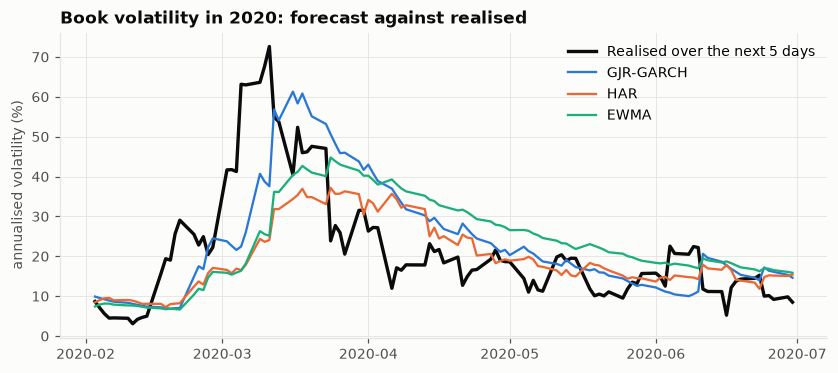

In [5]:
window = slice("2020-02-01", "2020-06-30")
book = forecasts[(forecasts["series_id"] == "book")].pivot(
    index="date", columns="model_id", values="forecast_var"
)
realised = forecasts[(forecasts["series_id"] == "book") & (forecasts["model_id"] == "har")].set_index("date")[
    "realised_var"
]
annualised = lambda variance: np.sqrt(252 * variance)  # noqa: E731 - percent, from daily variance in percent squared

fig, ax = plt.subplots()
ax.plot(
    realised.loc[window].index,
    annualised(realised.loc[window]),
    color=INK,
    linewidth=2.2,
    label="Realised over the next 5 days",
)
for model, label in [("gjr", "GJR-GARCH"), ("har", "HAR"), ("ewma", "EWMA")]:
    ax.plot(
        book.loc[window].index, annualised(book.loc[window, model]), color=MODEL_COLORS[model], label=label
    )
ax.set(title="Book volatility in 2020: forecast against realised", ylabel="annualised volatility (%)")
ax.legend(loc="upper right");

Forecasts are made at each close for the next five days, so the realised line leads them by construction. GJR rises first and tracks the late-February and March surge most closely; after the peak, in April and May, it stays above the realised level and HAR is the closer forecast.

## 4. Conclusions and consequences

| Finding | Consequence |
|---|---|
| GJR-GARCH: lowest QLIKE on the book, the bond and gold, significantly better than HAR on six series, best in 2020 | Champion volatility forecast for the parametric and filtered VaR |
| With the VIX, XGBoost is the most accurate on the three equity indices and significantly better than HAR there, but the least accurate on the book in 2020 | Not used for the book VaR; the VIX carries information for equity volatility |
| GJR's gain over HAR on the book is not significant at 5% (p = 0.080); in 2022 XGBoost and EWMA lead | The VaR is backtested by period, with EWMA as the benchmark |
| Range-based variance improves HAR on the euro area indices | Kept as an input; worth more with cleaner prices than Yahoo's |
| The GRU is significantly better than HAR on no series, and significantly worse on gold and the dollar | Not a candidate for the VaR |
| Machine learning helps only where an extra input carries information (the VIX for equities) | Consistent with Branco, Rubesam and Zevallos (2024): extra predictors help at short horizons, nonlinear models have no general edge; Christensen, Siggaard and Veliyev (2023) find larger gains with intraday realised variance |

**Limits.** Squared daily returns are a noisy proxy for realised variance; the smearing factor of the machine-learning models is estimated in-sample; their settings are fixed, not tuned; 42 tests at the 5% level are not corrected for multiple comparisons (a model confidence set, Hansen, Lunde and Nason, 2011, would be the next step).

## References

- Andersen, T. G., & Bollerslev, T. (1998). Answering the skeptics: Yes, standard volatility models do provide accurate forecasts. *International Economic Review*, 39(4), 885–905.
- Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327.
- Branco, R. R., Rubesam, A., & Zevallos, M. (2024). Forecasting realized volatility: Does anything beat linear models? *Journal of Empirical Finance*, 78, 101524.
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD Conference*, 785–794.
- Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014). Learning phrase representations using RNN encoder-decoder for statistical machine translation. *Proceedings of EMNLP 2014*, 1724–1734.
- Christensen, K., Siggaard, M., & Veliyev, B. (2023). A machine learning approach to volatility forecasting. *Journal of Financial Econometrics*, 21(5), 1680–1727.
- Corsi, F. (2009). A simple approximate long-memory model of realized volatility. *Journal of Financial Econometrics*, 7(2), 174–196.
- Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263.
- Duan, N. (1983). Smearing estimate: A nonparametric retransformation method. *Journal of the American Statistical Association*, 78(383), 605–610.
- Garman, M. B., & Klass, M. J. (1980). On the estimation of security price volatilities from historical data. *Journal of Business*, 53(1), 67–78.
- Glosten, L. R., Jagannathan, R., & Runkle, D. E. (1993). On the relation between the expected value and the volatility of the nominal excess return on stocks. *Journal of Finance*, 48(5), 1779–1801.
- Hansen, P. R., Lunde, A., & Nason, J. M. (2011). The model confidence set. *Econometrica*, 79(2), 453–497.
- Hansen, P. R., & Lunde, A. (2005). A forecast comparison of volatility models: Does anything beat a GARCH(1,1)? *Journal of Applied Econometrics*, 20(7), 873–889.
- J.P. Morgan/Reuters (1996). *RiskMetrics — Technical Document* (4th ed.).
- Newey, W. K., & West, K. D. (1994). Automatic lag selection in covariance matrix estimation. *Review of Economic Studies*, 61(4), 631–653.
- Patton, A. J. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics*, 160(1), 246–256.
- Yang, D., & Zhang, Q. (2000). Drift-independent volatility estimation based on high, low, open, and close prices. *Journal of Business*, 73(3), 477–491.